In [2]:

import zipfile
import os
import pandas as pd
import numpy as np

zip_path = "/content/archive (5).zip"
extract_path = "/content/nlp_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

csv_path = os.path.join(extract_path, "data_for_preprocessing.csv")

df = pd.read_csv(csv_path)

print("Dataset Loaded Successfully")
print("Shape:", df.shape)
print(df.head())
print(df.columns.tolist())


Dataset Loaded Successfully
Shape: (6069, 3)
   Unnamed: 0                                               Text Author
0           0  This study investigates the chemical compositi...     AI
1           1  This study explores the cultural history of oi...     AI
2           2   Isolation of human peripheral blood mononucle...  Human
3           3   Dynamic Bayesian Networks (DBNs) are probabil...  Human
4           4   Within volleyball, performance analysis is em...  Human
['Unnamed: 0', 'Text', 'Author']


In [3]:

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

df = df.dropna(subset=["Text", "Author"]).copy()

df["Text"] = df["Text"].astype(str).str.strip()
df["Author"] = df["Author"].astype(str).str.strip()

df = df[df["Text"] != ""]
df = df[df["Author"].isin(["AI", "Human"])]

df = df.drop_duplicates(subset=["Text", "Author"])
df = df.reset_index(drop=True)

print("Cleaned Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nLabel Distribution:")
print(df["Author"].value_counts())


Cleaned Shape: (6069, 2)

Missing Values:
Text      0
Author    0
dtype: int64

Label Distribution:
Author
AI       3069
Human    3000
Name: count, dtype: int64


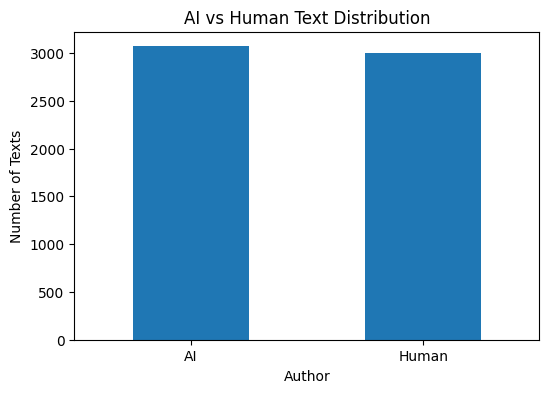

In [4]:

import matplotlib.pyplot as plt

df["Author"].value_counts().plot(
    kind="bar",
    figsize=(6, 4)
)

plt.title("AI vs Human Text Distribution")
plt.xlabel("Author")
plt.ylabel("Number of Texts")
plt.xticks(rotation=0)
plt.show()


In [5]:

import re
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def preprocess_text(text):
    text = clean_text(text)
    tokens = word_tokenize(text)

    processed_tokens = []

    for word in tokens:
        if word.isalpha() and word not in stop_words:
            processed_tokens.append(lemmatizer.lemmatize(word))

    return " ".join(processed_tokens)

df["Processed_Text"] = df["Text"].apply(preprocess_text)

print(df[["Text", "Processed_Text", "Author"]].head())


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


                                                Text  \
0  This study investigates the chemical compositi...   
1  This study explores the cultural history of oi...   
2  Isolation of human peripheral blood mononuclea...   
3  Dynamic Bayesian Networks (DBNs) are probabili...   
4  Within volleyball, performance analysis is emp...   

                                      Processed_Text Author  
0  study investigates chemical composition therma...     AI  
1  study explores cultural history oil wrestling ...     AI  
2  isolation human peripheral blood mononuclear c...  Human  
3  dynamic bayesian network dbns probabilistic mo...  Human  
4  within volleyball performance analysis employe...  Human  


In [6]:

X = df["Processed_Text"]
y = df["Author"]

print("Features:", X.shape)
print("Target:", y.shape)
print("\nLabels:", y.unique())


Features: (6069,)
Target: (6069,)

Labels: ['AI' 'Human']


In [7]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 4855
Testing Samples: 1214


In [8]:

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC

svm_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=30000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LinearSVC(random_state=42)
    )
])

svm_model.fit(X_train, y_train)

print("Model Training Completed!")


Model Training Completed!


Test Accuracy: 99.3410%

Classification Report:
              precision    recall  f1-score   support

          AI       0.99      1.00      0.99       614
       Human       1.00      0.99      0.99       600

    accuracy                           0.99      1214
   macro avg       0.99      0.99      0.99      1214
weighted avg       0.99      0.99      0.99      1214



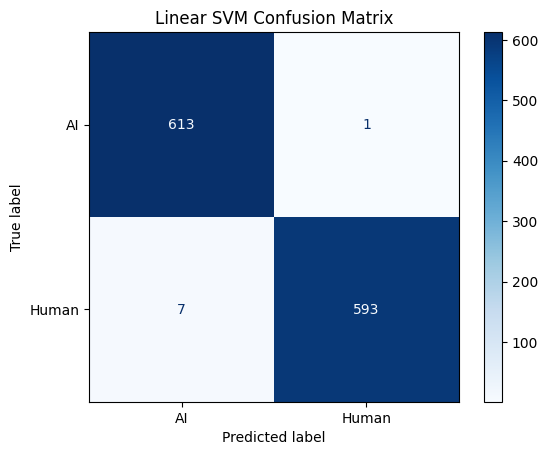

In [9]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_pred = svm_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4%}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["AI", "Human"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["AI", "Human"]
)

disp.plot(cmap="Blues")
plt.title("Linear SVM Confusion Matrix")
plt.show()


In [10]:

results = pd.DataFrame({
    "Text": df.loc[X_test.index, "Text"],
    "Actual": y_test,
    "Predicted": y_pred
})

wrong_predictions = results[
    results["Actual"] != results["Predicted"]
]

print("Total Test Samples:", len(results))
print("Correct Predictions:", len(results) - len(wrong_predictions))
print("Wrong Predictions:", len(wrong_predictions))

display(wrong_predictions.head(10))


Total Test Samples: 1214
Correct Predictions: 1206
Wrong Predictions: 8


,Text,Actual,Predicted
4574,To address the issue of low precision in senso...,Human,AI
863,"In this paper, we propose a dual-channel surfa...",Human,AI
4603,"During excavations in 2011, a peculiar archaeo...",Human,AI
2837,With the continuous advancement of network tra...,Human,AI
14,A new analysis of misdiagnosed fossil deposits...,Human,AI
5315,Background: Transferability of music education...,Human,AI
4070,Tight sandstone reservoirs usually experience ...,Human,AI
5725,This psychological experiment examines the rol...,AI,Human


In [11]:

import joblib

model_path = "/content/ai_human_svm_model.pkl"

joblib.dump(svm_model, model_path)

print("Model saved successfully!")
print("Saved at:", model_path)


Model saved successfully!
Saved at: /content/ai_human_svm_model.pkl


In [12]:

def predict_author(text):
    processed_text = preprocess_text(text)
    prediction = svm_model.predict([processed_text])[0]

    print("Prediction:", prediction)
    return prediction

sample_text = """
This study investigates the relationship between technology
and student performance using a systematic research method.
"""

predict_author(sample_text)


Prediction: AI


'AI'